# The Law of Large Numbers

Open in Google Colab (class): [![Open in Colab (class)](https://colab.research.google.com/assets/colab-badge.svg)]({{< var colabPrefix >}}class/{{< env QUARTO_DOCUMENT_FILE >}}))
Open in Google Colab (full): [![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)]({{< var colabPrefix >}}{{< env QUARTO_DOCUMENT_FILE >}})

If you toss a fair coin many times, the share of heads gets close to $1/2$. If you measure the same quantity many times, the average of the measurements gets close to the true value. The **law of large numbers** is the mathematical statement behind these everyday observations.

In this chapter we answer three questions:

1. How much does an average of random variables vary around its expected value?
2. How can we turn this variance into a statement about probabilities (Chebyshev's inequality)?
3. What does this tell us about the average of a large number of observations (the weak law of large numbers)?

At the end we also look at what goes wrong when the observations are *not* independent.

## Setup

Throughout the chapter we assume the following.

- $X_1, X_2, \ldots, X_n$ are **independent** random variables.
- They have the **same** expected value $E(X_i) = \mu$ and the **same** variance $\text{Var}(X_i) = \sigma^2$, with $\sigma^2 < \infty$.

The **sample average** (or sample mean) of the first $n$ variables is

$$
\bar{X}_n = \frac{1}{n} (X_1 + X_2 + \ldots + X_n) = \frac{1}{n} \sum_{i=1}^n X_i.
$$

Note that $\bar{X}_n$ is itself a random variable: if we repeat the whole experiment, we get a different value of the average.

## Two Properties of Sums

Everything in this chapter rests on two facts about the sum of two random variables. We state them here without proof.

### Motivation: the average of a sum is the sum of the averages

Take two small sets of numbers, paired up, for example the points of three students in two quizzes:

| Student | Quiz 1 ($x$) | Quiz 2 ($y$) | Total ($x + y$) |
|:-------:|:------------:|:------------:|:---------------:|
| A | 2 | 1 | 3 |
| B | 4 | 5 | 9 |
| C | 6 | 3 | 9 |

The averages of the columns are

$$
\bar{x} = \frac{2 + 4 + 6}{3} = 4, \qquad \bar{y} = \frac{1 + 5 + 3}{3} = 3, \qquad \overline{x + y} = \frac{3 + 9 + 9}{3} = 7.
$$

The average of the totals is $7 = 4 + 3$, the sum of the two averages. This is no coincidence. For any $m$ pairs of numbers, we can add all totals in any order, so we can collect the $x$-values and the $y$-values separately:

$$
\frac{1}{m} \sum_{i=1}^m (x_i + y_i) = \frac{1}{m} \sum_{i=1}^m x_i + \frac{1}{m} \sum_{i=1}^m y_i.
$$

Notice that we did not need the two columns to be unrelated: the equation holds for any pairing of the numbers.

The expected value is a (probability-weighted) average of the possible values of a random variable. If we think of $X_1$ and $X_2$ as two columns of numbers recorded in the same random experiment, the same argument suggests the following theorem.


:::{#thm-expected-value-sum .ex-class}
## Expected Value of a Sum

For any two random variables $X_1$ and $X_2$ with finite expected values (independent or not),

$$
E(X_1 + X_2) = E(X_1) + E(X_2).
$$

:::

:::{#thm-variance-sum .ex-class}
## Variance of a Sum of Independent Variables

For two **independent** random variables $X_1$ and $X_2$ with finite variances,

$$
\text{Var}(X_1 + X_2) = \text{Var}(X_1) + \text{Var}(X_2).
$$

:::

We will take the two theorems without a proof here, because 

*Why no proofs here?* Both statements are about the *joint* behavior of two random variables, and a proper proof needs the notion of a **bivariate distribution** (the joint distribution of two variables). We defer the proofs until we have introduced bivariate distributions.

Two remarks on how we use these theorems:

- Applying them repeatedly extends them to sums of $n$ variables: $E(X_1 + \ldots + X_n) = E(X_1) + \ldots + E(X_n)$, and, if $X_1, \ldots, X_n$ are independent, $\text{Var}(X_1 + \ldots + X_n) = \text{Var}(X_1) + \ldots + \text{Var}(X_n)$. (For the variance we use that the sum $X_1 + \ldots + X_k$ is independent of $X_{k+1}$ when all variables are independent.)
- For a constant $a$ and a random variable $Y$ we also use the rules $E(aY) = a E(Y)$ and $\text{Var}(aY) = a^2 \text{Var}(Y)$ from the chapter on properties of the expected value and the variance.

Note that the variance rule needs independence, while the rule for the expected value does not. We will see in the last section that this difference matters.

## The Expected Value of the Average

:::{#thm-expected-value-average .ex-class}
## Expected Value of the Average

Under the assumptions above,

$$
E(\bar{X}_n) = \mu.
$$

:::

:::{.callout-note collapse="true"}
## Proof (click to expand)

**Two variables first.** For $n = 2$ the average is $\bar{X}_2 = \frac{1}{2}(X_1 + X_2)$. Pull out the constant $\frac{1}{2}$ and apply @thm-expected-value-sum:

$$
E(\bar{X}_2) = \frac{1}{2} E(X_1 + X_2) = \frac{1}{2} \left( E(X_1) + E(X_2) \right) = \frac{1}{2} (\mu + \mu) = \mu.
$$

**General case.** The same steps work for $n$ variables. Pull out the constant $\frac{1}{n}$ and use the expected value of a sum (applied $n - 1$ times):

$$
E(\bar{X}_n) = \frac{1}{n} E\left(\sum_{i=1}^n X_i\right) = \frac{1}{n} \sum_{i=1}^n E(X_i).
$$

Every $E(X_i)$ equals $\mu$, so the sum has $n$ identical terms:

$$
\frac{1}{n} \sum_{i=1}^n E(X_i) = \frac{1}{n} \cdot n \mu = \mu.
$$

:::

On average, the sample average hits the target $\mu$. This alone is not enough for the law of large numbers: we also need to know how far a *single* realization of $\bar{X}_n$ can be from $\mu$. That is measured by the variance.

## The Variance of the Average

:::{#thm-variance-average .ex-class}
## Variance of the Average

Under the assumptions above (in particular, independence),

$$
\text{Var}(\bar{X}_n) = \frac{\sigma^2}{n}.
$$

:::

The more observations we average, the smaller the variance.

:::{.callout-note collapse="true"}
## Proof (click to expand)

**Two variables first.** For $n = 2$ we have $\bar{X}_2 = \frac{1}{2}(X_1 + X_2)$. Pull out the constant using $\text{Var}(aY) = a^2 \text{Var}(Y)$ with $a = \frac{1}{2}$, then use @thm-variance-sum (this is where independence is needed):

$$
\text{Var}(\bar{X}_2) = \frac{1}{4} \text{Var}(X_1 + X_2) = \frac{1}{4} \left( \text{Var}(X_1) + \text{Var}(X_2) \right) = \frac{1}{4} (\sigma^2 + \sigma^2) = \frac{\sigma^2}{2}.
$$

**General case.** The same steps work for $n$ variables. Pull out the constant $a = \frac{1}{n}$, which becomes $\frac{1}{n^2}$ after squaring:

$$
\text{Var}(\bar{X}_n) = \frac{1}{n^2} \text{Var}\left(\sum_{i=1}^n X_i\right).
$$

The variables are independent, so the variance of the sum is the sum of the variances:

$$
\frac{1}{n^2} \text{Var}\left(\sum_{i=1}^n X_i\right) = \frac{1}{n^2} \sum_{i=1}^n \text{Var}(X_i) = \frac{1}{n^2} \cdot n \sigma^2 = \frac{\sigma^2}{n}.
$$

:::

The standard deviation of the average is therefore $\sigma / \sqrt{n}$: to cut the typical deviation in half, we need four times as many observations.

## Markov's Inequality

To go from a statement about the *variance* to a statement about *probabilities*, we need two inequalities. The first one is simple but powerful.

:::{#thm-markov .ex-class}
## Markov's Inequality

Let $Y$ be a random variable with $Y \geq 0$ (it never takes negative values) and a finite expected value, and let $a > 0$. Then

$$
P(Y \geq a) \leq \frac{E(Y)}{a}.
$$

:::

:::{.callout-note collapse="true"}
## Proof (click to expand)

**The indicator.** For an event, such as $\{Y \geq a\}$, the **indicator** $I(Y \geq a)$ is the random variable defined by

$$
I(Y \geq a) =
\begin{cases}
1 & \text{if } Y \geq a, \\
0 & \text{if } Y < a.
\end{cases}
$$

It takes only the values $1$ and $0$, and $P(I(Y \geq a) = 1) = P(Y \geq a)$. Therefore its expected value is

$$
E\left(I(Y \geq a)\right) = 1 \cdot P(Y \geq a) + 0 \cdot P(Y < a) = P(Y \geq a).
$$

**The key inequality.** We claim that

$$
a \cdot I(Y \geq a) \leq Y
$$

in every possible outcome:

- If $Y \geq a$, then $I(Y \geq a) = 1$ and $a \cdot I(Y \geq a) = a \leq Y$.
- If $Y < a$, then $I(Y \geq a) = 0$ and $a \cdot I(Y \geq a) = 0 \leq Y$, because $Y \geq 0$. This is the place where we need $Y \geq 0$.

**Taking expected values.** When one random variable is always at most another, its expected value is at most the other's expected value:

$$
E\left(a \cdot I(Y \geq a)\right) \leq E(Y).
$$

The left-hand side equals $a \cdot E\left(I(Y \geq a)\right) = a \cdot P(Y \geq a)$. So $a \cdot P(Y \geq a) \leq E(Y)$, and dividing by $a > 0$ gives the claim.

:::

## Chebyshev's Inequality

Markov's inequality works for non-negative variables. The squared distance $(Y - E(Y))^2$ is always non-negative, so we can apply Markov's inequality to it.

:::{#thm-chebyshev .ex-class}
## Chebyshev's Inequality

Let $Y$ be a random variable with expected value $E(Y)$ and finite variance $\text{Var}(Y)$, and let $\varepsilon > 0$. Then

$$
P\left(|Y - E(Y)| \geq \varepsilon\right) \leq \frac{\text{Var}(Y)}{\varepsilon^2}.
$$

:::

:::{.callout-note collapse="true"}
## Proof (click to expand)

The event $|Y - E(Y)| \geq \varepsilon$ happens exactly when $(Y - E(Y))^2 \geq \varepsilon^2$ (both sides of the first inequality are non-negative, so we may square them). The two events are the same, so they have the same probability:

$$
P\left(|Y - E(Y)| \geq \varepsilon\right) = P\left((Y - E(Y))^2 \geq \varepsilon^2\right).
$$

Now apply Markov's inequality (@thm-markov) to the non-negative variable $(Y - E(Y))^2$ with $a = \varepsilon^2 > 0$:

$$
P\left((Y - E(Y))^2 \geq \varepsilon^2\right) \leq \frac{E\left[(Y - E(Y))^2\right]}{\varepsilon^2}.
$$

The numerator is the definition of the variance, $\text{Var}(Y)$. Combining the two displays gives the claim.

:::

Chebyshev's inequality is often written in terms of the standard deviation $\text{SD}(Y) = \sqrt{\text{Var}(Y)}$. Setting $\varepsilon = k \cdot \text{SD}(Y)$ gives $P(|Y - E(Y)| \geq k \cdot \text{SD}(Y)) \leq 1/k^2$, the form used in the elevator example in the chapter on continuous distributions.

The inequality holds for *every* distribution with a finite variance. The price for this generality is that the bound is often far from the true probability.

## The Weak Law of Large Numbers

Now we can combine the two results: Chebyshev's inequality applied to $\bar{X}_n$, whose variance we computed above.

:::{#thm-wlln .ex-class}
## Weak Law of Large Numbers

Let $X_1, X_2, \ldots$ be independent random variables with the same expected value $\mu$ and the same finite variance $\sigma^2$. Then for every $\varepsilon > 0$

$$
P\left(|\bar{X}_n - \mu| \geq \varepsilon\right) \leq \frac{\sigma^2}{n \varepsilon^2}
\quad \text{and therefore} \quad
\lim_{n \to \infty} P\left(|\bar{X}_n - \mu| \geq \varepsilon\right) = 0.
$$

:::

In words: no matter how small a margin $\varepsilon$ we choose, the probability that the average misses $\mu$ by more than $\varepsilon$ becomes as small as we like if $n$ is large enough. We say that $\bar{X}_n$ **converges in probability** to $\mu$.

:::{.callout-note collapse="true"}
## Proof (click to expand)

Apply Chebyshev's inequality (@thm-chebyshev) to $Y = \bar{X}_n$. By @thm-expected-value-average, $E(\bar{X}_n) = \mu$, so

$$
P\left(|\bar{X}_n - \mu| \geq \varepsilon\right) \leq \frac{\text{Var}(\bar{X}_n)}{\varepsilon^2}.
$$

By @thm-variance-average, $\text{Var}(\bar{X}_n) = \sigma^2 / n$. Substituting,

$$
P\left(|\bar{X}_n - \mu| \geq \varepsilon\right) \leq \frac{\sigma^2}{n \varepsilon^2}.
$$

This is the first claim. For the second, fix $\varepsilon > 0$. The number $\sigma^2 / \varepsilon^2$ is a fixed constant, so $\sigma^2 / (n \varepsilon^2) \to 0$ as $n \to \infty$. A probability is never negative, so

$$
0 \leq P\left(|\bar{X}_n - \mu| \geq \varepsilon\right) \leq \frac{\sigma^2}{n \varepsilon^2} \to 0,
$$

and the probability in the middle must converge to $0$ as well.

:::

The bound $\sigma^2 / (n\varepsilon^2)$ is explicit, so it also tells us **how many observations are enough**: to guarantee that $P(|\bar{X}_n - \mu| \geq \varepsilon) \leq \delta$ it is sufficient to take $n \geq \sigma^2 / (\delta \varepsilon^2)$.

## Seeing the Law in a Simulation

We roll a fair die many times and track the running average after each roll. The expected value of one roll is $\mu = 3.5$.

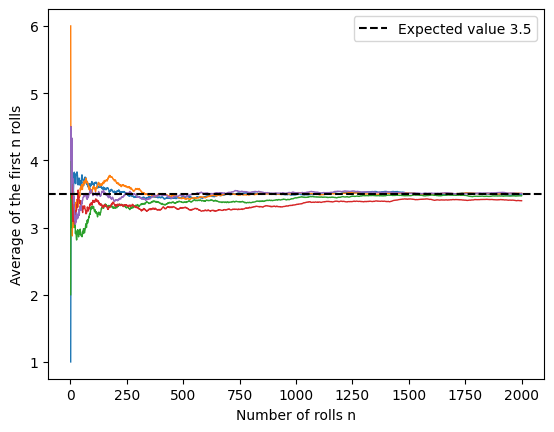

In [ ]:
#| label: fig-lln-running-mean
#| fig-cap: Running average of die rolls for five independent series. All series approach the expected value 3.5.
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(seed=42)

number_of_rolls = 2000
number_of_series = 5

rolls = rng.integers(low=1, high=7, size=(number_of_series, number_of_rolls))
number_of_observations = np.arange(1, number_of_rolls + 1)
running_mean = rolls.cumsum(axis=1) / number_of_observations

for series in running_mean:
    plt.plot(number_of_observations, series, linewidth=1)
plt.axhline(3.5, color="black", linestyle="--", label="Expected value 3.5")
plt.xlabel("Number of rolls n")
plt.ylabel("Average of the first n rolls")
plt.legend()
plt.show()

The averages fluctuate strongly for small $n$ and settle down around $3.5$ as $n$ grows, exactly as $\text{Var}(\bar{X}_n) = \sigma^2 / n$ predicts.

How good is the Chebyshev bound in the theorem? We toss a fair coin ($X_i \in \{0, 1\}$, $\mu = 0.5$, $\sigma^2 = 0.25$) $n$ times, repeat the experiment 10,000 times, and estimate $P(|\bar{X}_n - 0.5| \geq 0.1)$ from the repetitions.

In [ ]:
import pandas as pd

rng = np.random.default_rng(seed=123)

mu = 0.5
sigma_squared = 0.25
epsilon = 0.1
number_of_repetitions = 10_000

results = []
for n in [10, 50, 100, 500, 1000]:
    tosses = rng.integers(low=0, high=2, size=(number_of_repetitions, n))
    averages = tosses.mean(axis=1)
    results.append(
        {
            "n": n,
            "simulated probability": np.mean(np.abs(averages - mu) >= epsilon),
            "Chebyshev bound": min(1, sigma_squared / (n * epsilon**2)),
        }
    )

pd.DataFrame(results)

,n,simulated probability,Chebyshev bound
0,10,0.3453,1.000
1,50,0.1216,0.500
2,100,0.0304,0.250
3,500,0.0000,0.050
4,1000,0.0000,0.025


The simulated probabilities are always below the Chebyshev bound, as the theorem says they must be. They are also much smaller: Chebyshev's inequality is *valid for all distributions*, so it is not sharp for any particular one. The important message is that both quantities go to zero as $n$ grows.

## When the Law Breaks Down: Dependent Variables

Independence entered the proof in exactly one place: @thm-variance-sum, the variance of a sum. The rule for the expected value (@thm-expected-value-sum) holds without independence, so $E(\bar{X}_n) = \mu$ remains true for dependent variables. The variance rule does not remain true, and without it $\text{Var}(\bar{X}_n) = \sigma^2 / n$ fails, so Chebyshev's inequality no longer forces the probability to zero.

### Extreme case: perfect dependence

Let $X$ be a single toss of a fair coin ($1$ = heads, $0$ = tails, $\mu = 0.5$, $\sigma^2 = 0.25$) and suppose that $X_1 = X_2 = \ldots = X_n = X$, so that we copy the same toss $n$ times. These variables are as dependent as variables can be.

Then the average of the $n$ copies is just $X$ itself, however large $n$ is: $\bar{X}_n = \frac{1}{n} \cdot nX = X$. A fair coin takes only the values $0$ and $1$, so $|\bar{X}_n - 0.5| = 0.5$ with probability $1$, and for any $\varepsilon \leq 0.5$

$$
P\left(|\bar{X}_n - \mu| \geq \varepsilon\right) = 1 \quad \text{for every } n,
$$

which does not converge to $0$. The variance rule fails as well: $\text{Var}(X_1 + X_2) = \text{Var}(2X) = 4\sigma^2$, not $\text{Var}(X_1) + \text{Var}(X_2) = 2\sigma^2$.

More data does not help when the new data merely repeat what we already know.

### Partial dependence: a simulation

Between independence and perfect dependence lies a whole range. In the simulation below, the number $\rho$ between $0$ and $1$ controls how strongly the observations depend on each other: $\rho = 0$ gives independent standard normal observations ($\mu = 0$, $\sigma^2 = 1$) and $\rho = 1$ gives $n$ identical copies of a single observation. We look at how the average behaves for $\rho = 0$, $\rho = 0.5$ and $\rho = 1$.

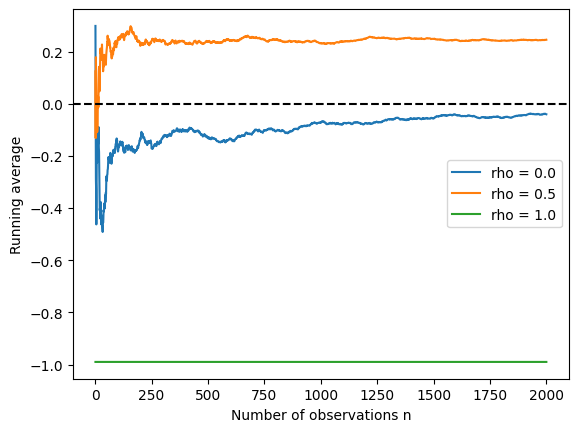

In [ ]:
#| label: fig-lln-dependent-running-mean
#| fig-cap: Running average of standard normal observations for three values of the dependence strength rho. Only for independent observations does the average settle at the expected value 0.
def simulate_dependent_observations(rng, rho, shape):
    """Standard normal observations along the last axis; rho = 0 independent, rho = 1 identical."""
    common_part = rng.standard_normal(size=shape[:-1] + (1,))
    own_part = rng.standard_normal(size=shape)
    return np.sqrt(rho) * common_part + np.sqrt(1 - rho) * own_part


rng = np.random.default_rng(seed=7)

number_of_observations_dep = 2000
number_of_observations_axis = np.arange(1, number_of_observations_dep + 1)

for rho in [0.0, 0.5, 1.0]:
    observations = simulate_dependent_observations(rng, rho, shape=(number_of_observations_dep,))
    running_mean_dep = observations.cumsum() / number_of_observations_axis
    plt.plot(number_of_observations_axis, running_mean_dep, label=f"rho = {rho}")

plt.axhline(0, color="black", linestyle="--")
plt.xlabel("Number of observations n")
plt.ylabel("Running average")
plt.legend()
plt.show()

For $\rho = 0$ the average converges to $\mu = 0$. For $\rho = 0.5$ and $\rho = 1$ it settles at some other level, which differs from run to run. Rerun the cell with a different seed to see this.

Finally, we compare the simulated variance of $\bar{X}_n$ across many repetitions for several values of $\rho$ and $n$.

In [ ]:
rng = np.random.default_rng(seed=2024)

number_of_repetitions = 20_000
rows = []
for rho in [0.0, 0.5, 1.0]:
    for n in [10, 100, 1000]:
        observations = simulate_dependent_observations(rng, rho, shape=(number_of_repetitions, n))
        averages = observations.mean(axis=1)
        rows.append(
            {
                "rho": rho,
                "n": n,
                "simulated Var(mean)": averages.var(),
            }
        )

pd.DataFrame(rows).round(4)

,rho,n,simulated Var(mean)
0,0.0,10,0.1011
1,0.0,100,0.0101
2,0.0,1000,0.0010
3,0.5,10,0.5470
4,0.5,100,0.5057
5,0.5,1000,0.4973
6,1.0,10,0.9864
7,1.0,100,1.0005
8,1.0,1000,1.0200


For $\rho = 0$ (independent observations) the variance of the average falls like $\sigma^2/n = 1/n$, as in @thm-variance-average. For $\rho > 0$ it stops decreasing and levels off at a positive value close to $\rho$, so the average does not concentrate around $\mu$ however many observations we take.

*Remark.* Independence is sufficient but not necessary. If the dependence between $X_i$ and $X_j$ fades quickly as $|i - j|$ grows (weak dependence, as in many time series), the variance of the average still converges to zero and a law of large numbers continues to hold. We do not prove this here.

## Exercises

:::{#exr-lln-coin-tosses .ex-class}
A fair coin is tossed $n$ times. Use the bound from @thm-wlln to find a number of tosses $n$ that guarantees $P(|\bar{X}_n - 0.5| \geq 0.05) \leq 0.05$. Is the bound likely to be sharp?
:::

:::{#exr-lln-correlated .ex-class}
Modify the simulation of dependent observations to use $\rho = 0.3$ and $n = 100$. Estimate $\text{Var}(\bar{X}_{100})$ and compare it with $\sigma^2/n$, the value we would get for 100 independent observations. Which value does the simulation with $n = 1000$ and $n = 10{,}000$ suggest for large $n$?
:::

:::{#exr-lln-infinite-variance .ex-class}
Which step of the proof of @thm-wlln breaks down if $\sigma^2 = \infty$? Does this mean that the average cannot converge to $\mu$?
:::